In [1]:
from background.modules.exchange_upbit import ExChangeUpbit
from background.modules.exchange__calculator import ExChangeCalculator
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import os

import datetime

In [2]:
interval = "minute5"
count = 200
days = 93

In [3]:
upbit = ExChangeUpbit()
upbit.set_ticker("KRW-BTC")

True

In [4]:


end_dt = datetime.datetime.now()
start_dt = end_dt - datetime.timedelta(days=days)

dfs = []
to = end_dt
max_call = int((days * 24 * 12) / count) + 2

for _ in range(max_call):
    df = upbit.get_ohlcv(
        interval=interval,
        date=to.strftime("%Y-%m-%d %H:%M:%S"),
        count=count
    )

    if df is None or df.empty:
        break

    dfs.append(df)

    oldest_dt = df["datetime"].iloc[0]

    # 30일 이전이면 종료
    if oldest_dt <= start_dt:
        break

    # 다음 호출 기준점
    to = oldest_dt - datetime.timedelta(minutes=5)

df_combined = (
    pd.concat(dfs)
    .drop_duplicates(subset="datetime")
    .sort_values("datetime")
    .reset_index(drop=True)
)

In [5]:
df_combined.head()

,open,high,low,close,volume,value,datetime
0,138460000.0,138661000.0,138402000.0,138510000.0,3.150144,4.364662e+08,2025-12-10 04:50:00
1,138510000.0,138599000.0,138351000.0,138503000.0,3.496045,4.842208e+08,2025-12-10 04:55:00
2,138366000.0,138500000.0,138114000.0,138150000.0,7.310376,1.011314e+09,2025-12-10 05:00:00
3,138114000.0,138378000.0,138100000.0,138304000.0,8.926086,1.233880e+09,2025-12-10 05:05:00
4,138207000.0,138506000.0,138206000.0,138283000.0,3.231209,4.470808e+08,2025-12-10 05:10:00


In [6]:
def apply_all_features(calculator):
    methods = [
        getattr(calculator, m)
        for m in dir(calculator)
        if callable(getattr(calculator, m))
        and m.startswith("set_")
        and m not in ["set_ohlcv"]
    ]
    
    for method in methods:
        try:
            method()
        except Exception:
            pass

    return calculator.get_df()

calculator = ExChangeCalculator(df_combined)
new_df = apply_all_features(calculator)
new_df.head(100)

,open,high,low,close,volume,value,datetime,prev_close,prev_high,prev_low,...,volume_volatility,volume_zscore_20,cum_volume,cum_vwap,vwap,weekday,weekday_cos,weekday_num,weekday_sin,wick_ratio
0,138460000.0,138661000.0,138402000.0,138510000.0,3.150144,4.364662e+08,2025-12-10 04:50:00,NaN,NaN,NaN,...,NaN,NaN,3.150144,4.363716e+08,1.385243e+08,2,-0.222521,2,0.974928,0.806950
1,138510000.0,138599000.0,138351000.0,138503000.0,3.496045,4.842208e+08,2025-12-10 04:55:00,138510000.0,138661000.0,138402000.0,...,NaN,NaN,6.646188,9.205190e+08,1.385033e+08,2,-0.222521,2,0.974928,0.971774
2,138366000.0,138500000.0,138114000.0,138150000.0,7.310376,1.011314e+09,2025-12-10 05:00:00,138503000.0,138599000.0,138351000.0,...,NaN,NaN,13.956564,1.931213e+09,1.383731e+08,2,-0.222521,2,0.974928,0.440415
3,138114000.0,138378000.0,138100000.0,138304000.0,8.926086,1.233880e+09,2025-12-10 05:05:00,138150000.0,138500000.0,138114000.0,...,NaN,NaN,22.882650,3.165339e+09,1.383292e+08,2,-0.222521,2,0.974928,0.316547
4,138207000.0,138506000.0,138206000.0,138283000.0,3.231209,4.470808e+08,2025-12-10 05:10:00,138304000.0,138378000.0,138100000.0,...,NaN,NaN,26.113859,3.612318e+09,1.383295e+08,2,-0.222521,2,0.974928,0.746667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,137095000.0,137095000.0,137018000.0,137072000.0,3.933415,5.391415e+08,2025-12-10 12:45:00,137094000.0,137095000.0,137089000.0,...,2.109217,0.326666,573.317454,7.862296e+10,1.371369e+08,2,-0.222521,2,0.974928,0.701299
96,137071000.0,137100000.0,137071000.0,137099000.0,2.455519,3.366376e+08,2025-12-10 12:50:00,137072000.0,137095000.0,137018000.0,...,2.017756,-0.426277,575.772974,7.895959e+10,1.371367e+08,2,-0.222521,2,0.974928,0.034483
97,137099000.0,137148000.0,137099000.0,137116000.0,1.852869,2.540365e+08,2025-12-10 12:55:00,137099000.0,137100000.0,137071000.0,...,2.043774,-0.740181,577.625843,7.921366e+10,1.371366e+08,2,-0.222521,2,0.974928,0.653061
98,137111000.0,137116000.0,137096000.0,137116000.0,1.959683,2.686928e+08,2025-12-10 13:00:00,137116000.0,137148000.0,137099000.0,...,0.791414,-0.614754,579.585526,7.948235e+10,1.371365e+08,2,-0.222521,2,0.974928,0.750000


In [7]:
def create_target(df, horizon=12):  # 예: minute5 기준 12 = 1시간
    df = df.copy()
    df["future_close"] = df["close"].shift(-horizon)
    df["return"] = (df["future_close"] - df["close"]) / df["close"]

    df["target"] = 0
    df.loc[df["return"] >= 0.005, "target"] = 1
    df.loc[df["return"] <= -0.005, "target"] = -1

    #df = df.dropna()
    return df

new_df2 = create_target(new_df, 15)
new_df2.head(100)

,open,high,low,close,volume,value,datetime,prev_close,prev_high,prev_low,...,cum_volume,cum_vwap,vwap,weekday,weekday_cos,weekday_num,weekday_sin,wick_ratio,return,target
0,138460000.0,138661000.0,138402000.0,138510000.0,3.150144,4.364662e+08,2025-12-10 04:50:00,NaN,NaN,NaN,...,3.150144,4.363716e+08,1.385243e+08,2,-0.222521,2,0.974928,0.806950,-0.007162,-1
1,138510000.0,138599000.0,138351000.0,138503000.0,3.496045,4.842208e+08,2025-12-10 04:55:00,138510000.0,138661000.0,138402000.0,...,6.646188,9.205190e+08,1.385033e+08,2,-0.222521,2,0.974928,0.971774,-0.008173,-1
2,138366000.0,138500000.0,138114000.0,138150000.0,7.310376,1.011314e+09,2025-12-10 05:00:00,138503000.0,138599000.0,138351000.0,...,13.956564,1.931213e+09,1.383731e+08,2,-0.222521,2,0.974928,0.440415,-0.006145,-1
3,138114000.0,138378000.0,138100000.0,138304000.0,8.926086,1.233880e+09,2025-12-10 05:05:00,138150000.0,138500000.0,138114000.0,...,22.882650,3.165339e+09,1.383292e+08,2,-0.222521,2,0.974928,0.316547,-0.005936,-1
4,138207000.0,138506000.0,138206000.0,138283000.0,3.231209,4.470808e+08,2025-12-10 05:10:00,138304000.0,138378000.0,138100000.0,...,26.113859,3.612318e+09,1.383295e+08,2,-0.222521,2,0.974928,0.746667,-0.005612,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,137095000.0,137095000.0,137018000.0,137072000.0,3.933415,5.391415e+08,2025-12-10 12:45:00,137094000.0,137095000.0,137089000.0,...,573.317454,7.862296e+10,1.371369e+08,2,-0.222521,2,0.974928,0.701299,0.002947,0
96,137071000.0,137100000.0,137071000.0,137099000.0,2.455519,3.366376e+08,2025-12-10 12:50:00,137072000.0,137095000.0,137018000.0,...,575.772974,7.895959e+10,1.371367e+08,2,-0.222521,2,0.974928,0.034483,0.003107,0
97,137099000.0,137148000.0,137099000.0,137116000.0,1.852869,2.540365e+08,2025-12-10 12:55:00,137099000.0,137100000.0,137071000.0,...,577.625843,7.921366e+10,1.371366e+08,2,-0.222521,2,0.974928,0.653061,0.003121,0
98,137111000.0,137116000.0,137096000.0,137116000.0,1.959683,2.686928e+08,2025-12-10 13:00:00,137116000.0,137148000.0,137099000.0,...,579.585526,7.948235e+10,1.371365e+08,2,-0.222521,2,0.974928,0.750000,0.003931,0


In [8]:
def run_feature_importance(upbit_module, interval="minute5"):

    results = {}

    for name, count in periods.items():

        print(f"processing {name} ...")

        df = upbit_module.get_ohlcv(interval=interval, count=count)

        calculator = ExChangeCalculator(df)
        df = apply_all_features(calculator)

        df = create_target(df, horizon=12)  # 1시간 후 기준

        importance = get_feature_importance(df)

        results[name] = importance

    return results



In [9]:
from background.modules.exchange_upbit import ExChangeUpbit
from background.modules.exchange__calculator import ExChangeCalculator

from sklearn.ensemble import RandomForestClassifier

import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import os

import seaborn as sns

import datetime

In [10]:

def apply_all_features(calculator):
    methods = [
        getattr(calculator, m)
        for m in dir(calculator)
        if callable(getattr(calculator, m))
        and m.startswith("set_")
        and m not in ["set_ohlcv"]
    ]
    
    for method in methods:
        try:
            method()
        except Exception:
            pass

    return calculator.get_df()

def create_target(df, horizon=12):  # 예: minute5 기준 12 = 1시간
    df = df.copy()
    df["future_close"] = df["close"].shift(-horizon)
    df["return"] = (df["future_close"] - df["close"]) / df["close"]

    df["target"] = 0
    df.loc[df["return"] >= 0.005, "target"] = 1
    df.loc[df["return"] <= -0.005, "target"] = -1

    #df = df.dropna()
    return df

def cut_by_days(end_dt, df, days):
    start = end_dt - datetime.timedelta(days=days)
    return df[df["datetime"] >= start].copy()

def get_feature_importance(df):

    df = df.copy()

    X = df.drop(columns=["datetime", "target", "future_close", "return", "future_change", "future_change_pct", "future_direction_num"], errors="ignore")
    y = df["target"]

    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(0)

    valid_idx = X.index.intersection(y.index)
    X = X.loc[valid_idx]
    y = y.loc[valid_idx]

    if len(y.unique()) < 2:
        print("⚠ target class 부족")
        return None

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    model.fit(X, y)

    importance = pd.DataFrame({
        "feature": X.columns,
        "importance": model.feature_importances_
    }).sort_values(by="importance", ascending=False)

    return importance.head(30)

def plot_importance_pretty(importance_df, title="Feature Importance"):

    plt.figure(figsize=(10, 8))
    sns.barplot(
        x="importance",
        y="feature",
        data=importance_df,
        orient="h"
    )
    
    plt.title(title)
    plt.tight_layout()
    plt.show()

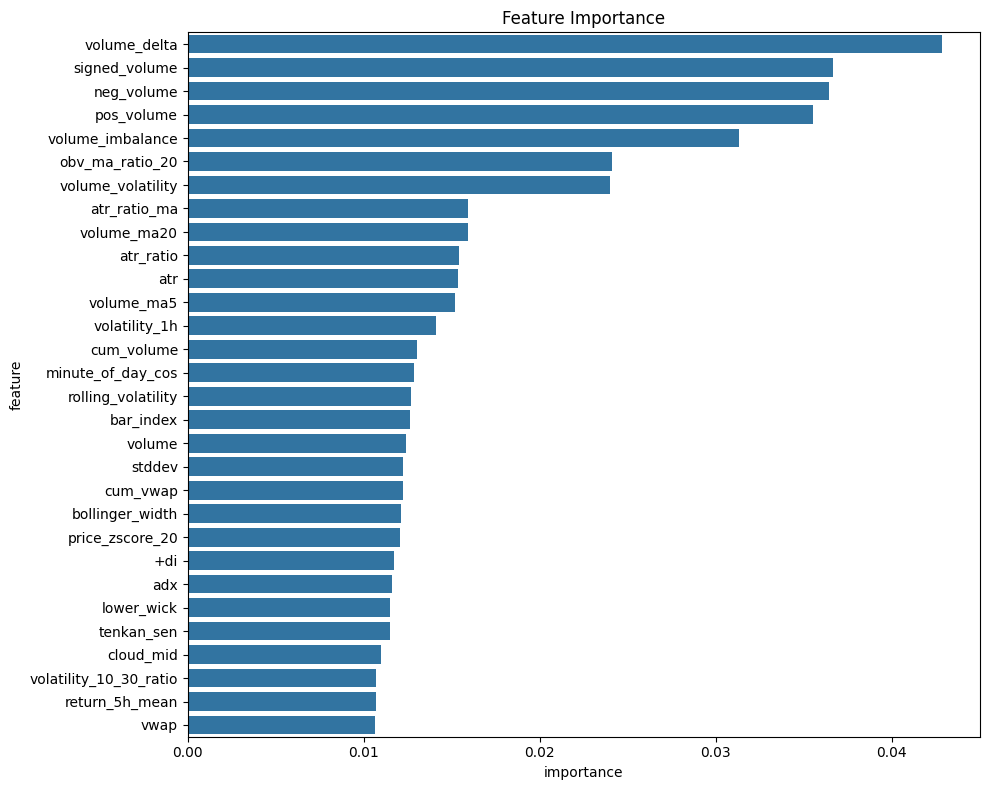

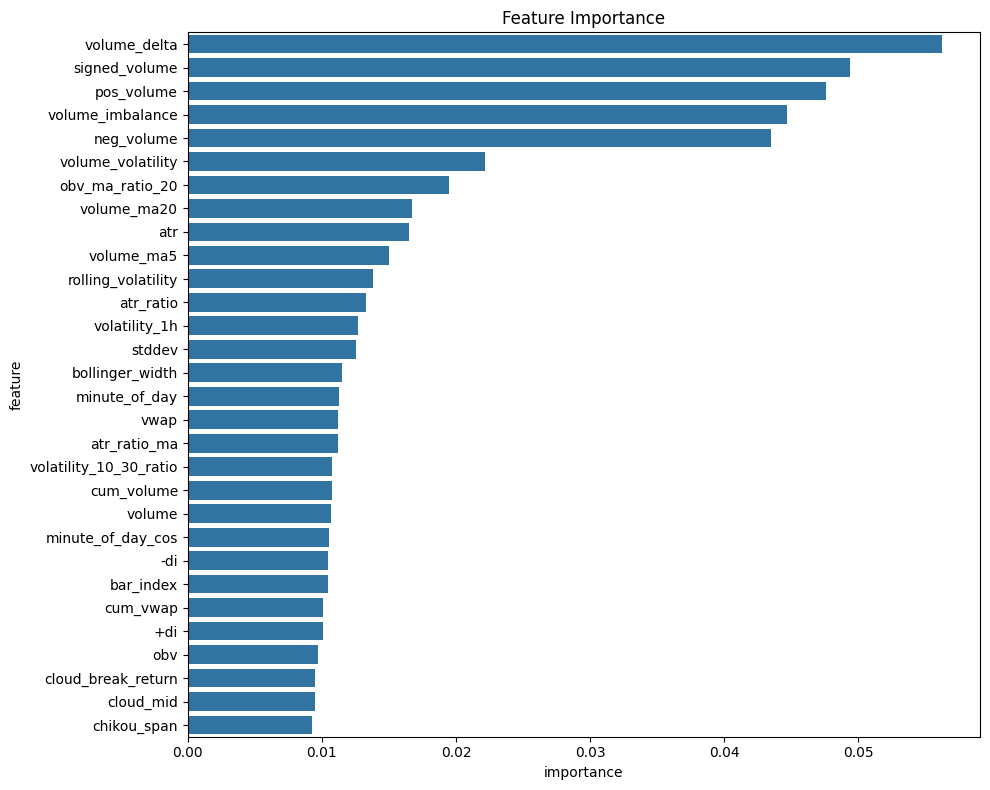

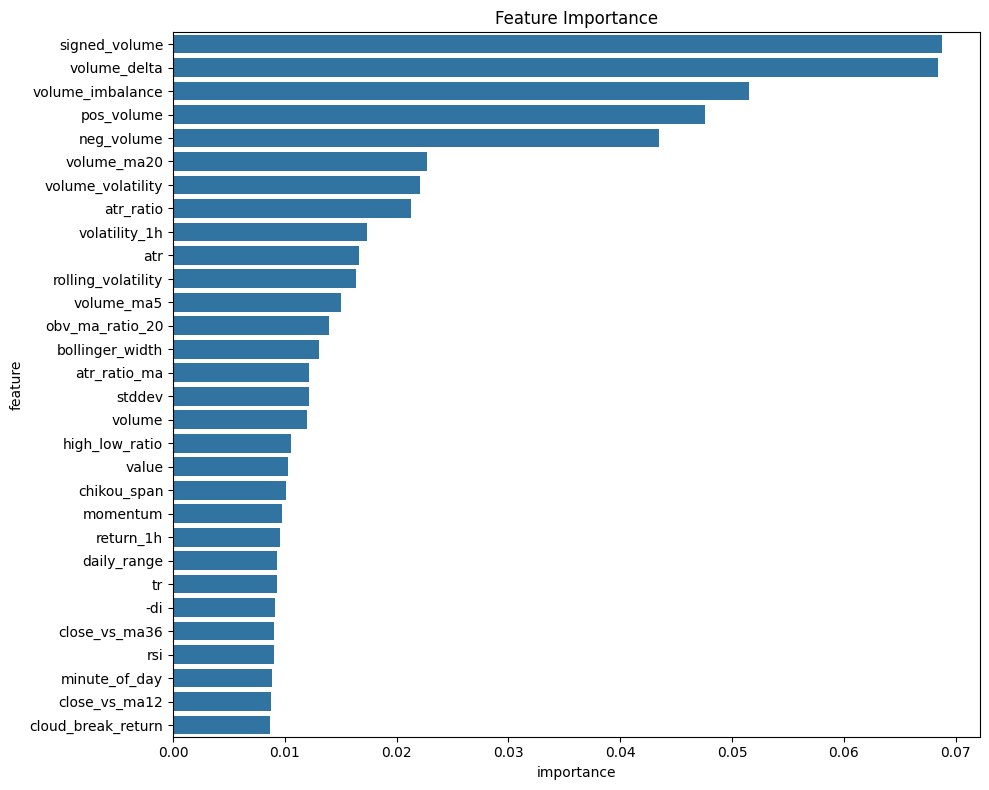

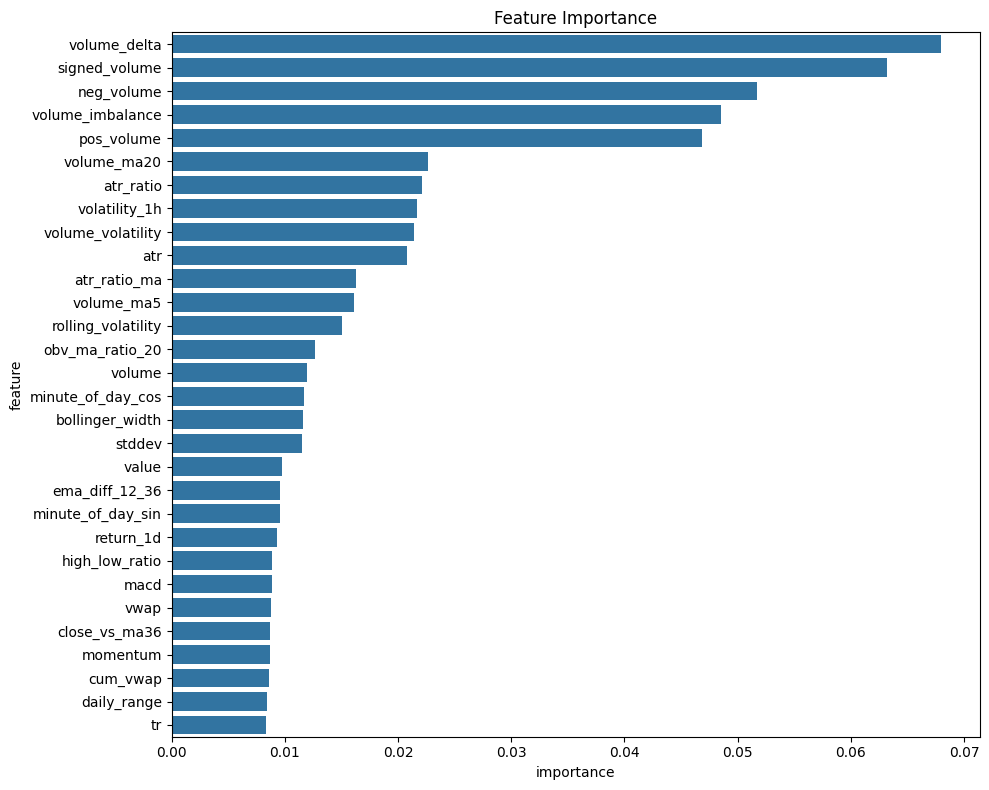

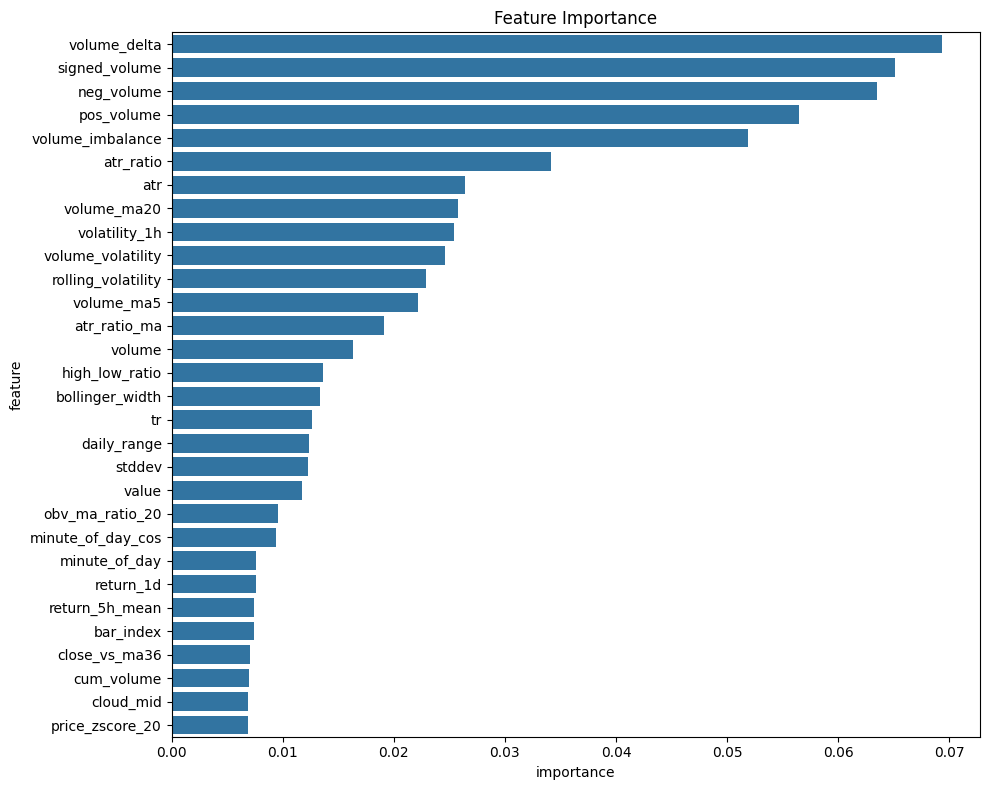

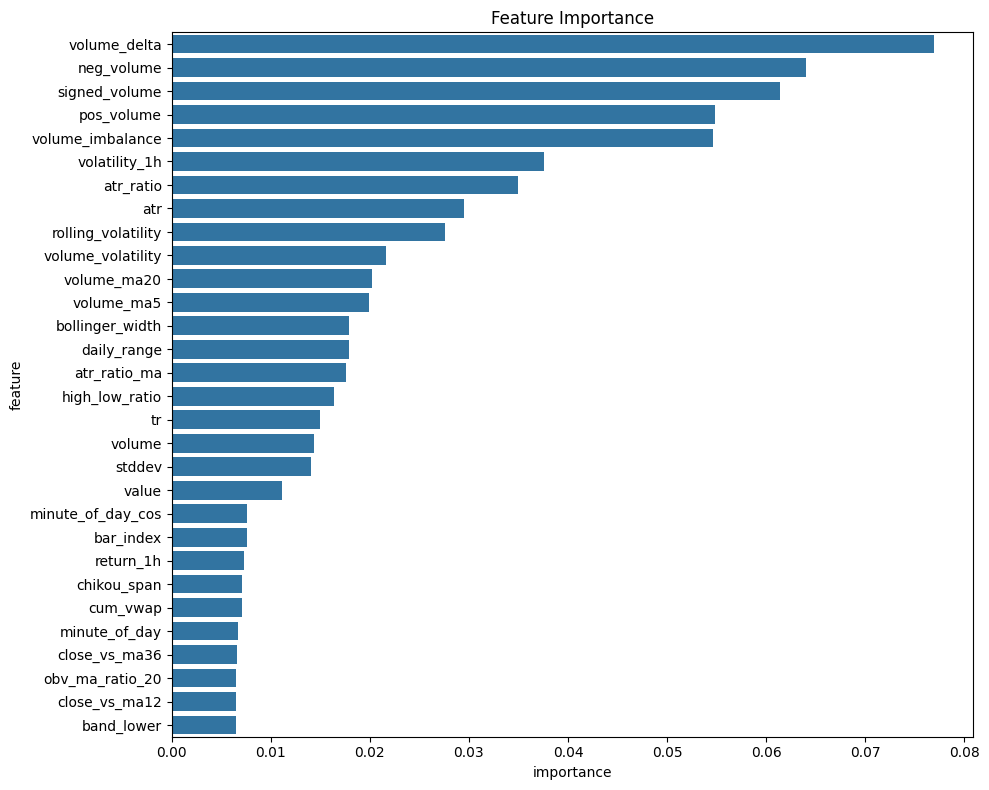

In [11]:

interval = "minute5"
count = 200
days = 93

DAY_COUNT = 288

periods = {
    "3_month": DAY_COUNT * 90,
    "2_month": DAY_COUNT * 60,
    "1_month": DAY_COUNT * 30,
    "3_week":  DAY_COUNT * 21,
    "2_week":  DAY_COUNT * 14,
    "1_week":  DAY_COUNT * 7,
}

upbit = ExChangeUpbit()
upbit.set_ticker("KRW-BTC")

end_dt = datetime.datetime.now()
start_dt = end_dt - datetime.timedelta(days=days)

dfs = []
to = end_dt
max_call = int((days * 24 * 12) / count) + 2

for _ in range(max_call):
    df = upbit.get_ohlcv(
        interval=interval,
        date=to.strftime("%Y-%m-%d %H:%M:%S"),
        count=count
    )

    if df is None or df.empty:
        break

    dfs.append(df)

    oldest_dt = df["datetime"].iloc[0]

    # 30일 이전이면 종료
    if oldest_dt <= start_dt:
        break

    # 다음 호출 기준점
    to = oldest_dt - datetime.timedelta(minutes=5)

df_combined = (
    pd.concat(dfs)
    .drop_duplicates(subset="datetime")
    .sort_values("datetime")
    .reset_index(drop=True)
)

calculator = ExChangeCalculator(df_combined)
df = apply_all_features(calculator)
df = create_target(df, horizon=3)  # 15분 뒤 기준

df_1w  = cut_by_days(end_dt, df, 7)
df_2w  = cut_by_days(end_dt, df, 14)
df_3w  = cut_by_days(end_dt, df, 21)
df_1m  = cut_by_days(end_dt, df, 30)
df_2m  = cut_by_days(end_dt, df, 60)
df_3m  = df

df_1w = get_feature_importance(df_1w)
plot_importance_pretty(df_1w)

df_2w = get_feature_importance(df_2w)
plot_importance_pretty(df_2w)

df_3w = get_feature_importance(df_3w)
plot_importance_pretty(df_3w)

df_1m = get_feature_importance(df_1m)
plot_importance_pretty(df_1m)

df_2m = get_feature_importance(df_2m)
plot_importance_pretty(df_2m)

df_3m = get_feature_importance(df_3m)
plot_importance_pretty(df_3m)

In [12]:
pip install jupyterlab_widgets


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
import shap

def get_feature_direction(df):

    df = df.copy()

    X = df.drop(columns=["datetime", "target", "future_close", "return"], errors="ignore")
    y = df["target"]

    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    model.fit(X, y)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)

    # shap version 대응
    if isinstance(shap_values, list):
        shap_matrix = shap_values[1]
    else:
        shap_matrix = shap_values[:, :, 1]

    shap_df = pd.DataFrame(shap_matrix, columns=X.columns)

    result = pd.DataFrame({
        "feature": X.columns,
        "mean_shap": shap_df.mean()
    })

    up = result.sort_values("mean_shap", ascending=False).head(15)
    down = result.sort_values("mean_shap").head(15)

    return up, down

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


In [14]:
up, down = get_feature_direction(df)

In [15]:
up

,feature,mean_shap
future_change_pct,future_change_pct,0.036389
future_change,future_change,0.032244
atr_ratio,atr_ratio,0.020450
rolling_volatility,rolling_volatility,0.019817
volatility_1h,volatility_1h,0.018403
atr,atr,0.014566
volume_ma20,volume_ma20,0.013246
atr_ratio_ma,atr_ratio_ma,0.011403
volume_ma5,volume_ma5,0.010885
volume_volatility,volume_volatility,0.010486


In [16]:
down

,feature,mean_shap
volume_imbalance,volume_imbalance,-1.657865e-03
future_direction_num,future_direction_num,-1.063930e-03
cdlxsidegap3methods,cdlxsidegap3methods,0.000000e+00
cdlupsidegap2crows,cdlupsidegap2crows,0.000000e+00
cdltristar,cdltristar,0.000000e+00
cdlhighwave,cdlhighwave,0.000000e+00
cdlgapsidesidewhite,cdlgapsidesidewhite,0.000000e+00
cdldojistar,cdldojistar,0.000000e+00
cdlconcealbabyswall,cdlconcealbabyswall,0.000000e+00
cdlabandonedbaby,cdlabandonedbaby,0.000000e+00
